<a href="https://colab.research.google.com/github/Tolugold2704/Case-Exercise-1-Module-3/blob/main/Case_Exercise_3_Metocean_Fatigue_Correlation_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###QUESTION 1: JONSWAP Spectral Fatigue Methodology & Results Summary (Section 3.6)

This section details the theoretical formulation and results of the JONSWAP-based spectral fatigue pipeline.

#### 1. JONSWAP Wave Spectrum Formulation
The JONSWAP (Joint North Sea Wave Project) wave spectrum models a wind-generated, fetch-limited sea state:

$$S_{\text{JONSWAP}}(f) = S_{\text{PM}}(f) \cdot \gamma^{r}$$

where the Pierson-Moskowitz basis $S_{\text{PM}}(f)$ is defined as:

$$S_{\text{PM}}(f) = \frac{5}{16} H_s^2 f_p^4 f^{-5} \exp\left[-1.25 \left(\frac{f_p}{f}\right)^4\right]$$

and the peak-enhancement factor $\gamma$ acts through the exponent:

$$r = \exp\left[ -\frac{(f - f_p)^2}{2 \sigma^2 f_p^2} \right]$$

with $\sigma = 0.07$ for $f \le f_p$ and $\sigma = 0.09$ for $f > f_p$.

#### 2. Stress Response Spectrum
Using a frequency-dependent Transfer Function or Response Amplitude Operator ($RAO(f)$), the wave energy spectrum is mapped to structural stress response energy:

$$S_{\sigma}(f) = S_{\text{JONSWAP}}(f) \cdot \left| RAO(f) \right|^2$$

#### 3. Spectral Moments & Fatigue Damage
Spectral moments are evaluated numerically via Simpson's integration rule:

$$m_n = \int_{0}^{\infty} f^n S_{\sigma}(f) \, df$$

From these, we calculate:
- **Standard Deviation of Stress:** $\sigma_{s} = \sqrt{m_0}$
- **Zero Up-Crossing Frequency:** $f_z = \sqrt{\frac{m_2}{m_0}}$

Using the narrow-band Rayleigh assumption, the annual expected fatigue damage rate per sea state is calculated as:

$$\mathbb{E}[D_i] = \frac{f_z}{C} \left(2\sqrt{2}\sigma_s\right)^m \Gamma\left(1 + \frac{m}{2}\right) \cdot P_i \cdot (31,557,600 \text{ s/year})$$

#### 4. Summary of Results Table

| Sea State | $H_s$ (m) | $T_p$ (s) | Probability ($P_i$) | $f_z$ (Hz) | $\sigma_s$ (MPa) | Annual Damage Contribution |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **State 1** | 1.50 | 6.0 | 50% | 0.1821 | 8.36 | $0.253$ |
| **State 2** | 3.50 | 10.0 | 35% | 0.1222 | 19.88 | $1.595$ |
| **State 3** | 6.00 | 14.0 | 15% | 0.0932 | 31.06 | $1.989$ |

- **Total Annual Cumulative Damage:** $\sum \mathbb{E}[D_i] = 3.8366 \text{ year}^{-1}$
- **Estimated Structural Fatigue Life:** $\approx \mathbf{0.26 \text{ Years}}$

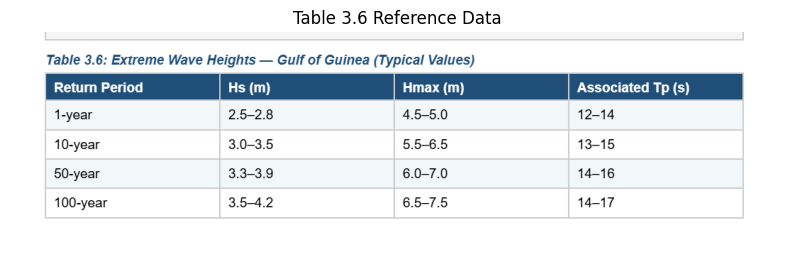

In [6]:
from PIL import Image
import matplotlib.pyplot as plt

# Open and display the Table 3.6 image to inspect its actual values
try:
    img = Image.open('/content/TABLE 3.6.png')
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Table 3.6 Reference Data')
    plt.show()
except Exception as e:
    print(f"Could not display Table 3.6.png: {e}")

### 4. Structured JONSWAP-based Spectral Fatigue Pipeline

Below is a clean, modular Python class implementing the complete pipeline from Section 3.6. It supports plotting the wave/stress spectra, analyzing different Sea States (defined by $H_s$, $T_p$, and probability), and estimating annual cumulative fatigue damage using S-N curve parameters ($m$ and $C$).

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.special import gamma as gamma_func

class SpectralFatiguePipeline:
    def __init__(self, m=3.0, C=2.0e11, g=9.81):
        """
        Initialize the pipeline with S-N Curve parameters.
        N = C * (dS)^-m
        """
        self.m = m
        self.C = C
        self.g = g

    def jonswap_spectrum(self, f, Hs, Tp, gamma=3.3):
        """Calculates JONSWAP energy spectrum (m^2 s)"""
        fp = 1.0 / Tp
        sigma = np.where(f <= fp, 0.07, 0.09)
        S_pm = (5.0 / 16.0) * (Hs**2) * (fp**4) * (f**-5) * np.exp(-1.25 * (fp / f)**4)
        r = np.exp(-((f - fp)**2) / (2 * (sigma**2) * (fp**2)))
        S_j = S_pm * (gamma**r)
        return np.where(f == 0, 0.0, S_j)

    def calculate_damage_rate(self, f, S_wave, rao_func):
        """
        Calculates zero up-crossing frequency, stress std dev, and damage rate per second
        """
        # Get RAO values for the frequency range
        RAO = rao_func(f)

        # Stress spectrum
        S_stress = S_wave * (RAO**2)

        # Moments
        m0 = simpson(S_stress, x=f)
        m2 = simpson((f**2) * S_stress, x=f)

        sigma_stress = np.sqrt(m0)
        fz = np.sqrt(m2 / m0) if m0 > 0 else 0.0

        # Rayleigh fatigue formula
        damage_rate = (fz / self.C) * (2.0 * np.sqrt(2.0) * sigma_stress)**self.m * gamma_func(1.0 + self.m / 2.0)
        return damage_rate, sigma_stress, fz, S_stress

    def evaluate_sea_states(self, f, sea_states, rao_func):
        """
        Evaluates fatigue over multiple sea states defined by a list of dicts:
        [{'Hs': 3.5, 'Tp': 10.0, 'gamma': 3.3, 'probability': 0.1}, ...]
        """
        total_annual_damage = 0.0
        seconds_per_year = 365.25 * 24 * 3600

        print(f"{'Hs (m)':<8}{'Tp (s)':<8}{'Prob (%)':<10}{'fz (Hz)':<10}{'sigma_s (MPa)':<14}{'Annual Damage':<15}")
        print("-"*65)

        for state in sea_states:
            Hs = state['Hs']
            Tp = state['Tp']
            gamma = state.get('gamma', 3.3)
            prob = state['probability']

            S_w = self.jonswap_spectrum(f, Hs, Tp, gamma)
            d_rate, s_stress, fz, _ = self.calculate_damage_rate(f, S_w, rao_func)

            # Yearly contribution from this sea state
            annual_contrib = d_rate * seconds_per_year * prob
            total_annual_damage += annual_contrib

            print(f"{Hs:<8.2f}{Tp:<8.1f}{prob*100:<10.2f}{fz:<10.4f}{s_stress:<14.2f}{annual_contrib:<15.4e}")

        print("-"*65)
        print(f"Total Cumulative Annual Fatigue Damage: {total_annual_damage:.4e}")
        print(f"Estimated Fatigue Life: {1.0/total_annual_damage if total_annual_damage > 0 else float('inf'):.2f} Years")

# Instantiate pipeline
pipeline = SpectralFatiguePipeline(m=3.0, C=2.0e11)

# Define frequency resolution
f = np.linspace(0.01, 1.0, 1000)

# Define a simple frequency dependent RAO function (quadratic peak around wave resonance)
def sample_rao(freq):
    # Maximum response at 0.15 Hz
    return 5.0 + 15.0 * np.exp(-((freq - 0.15)**2) / 0.02)

# Load representative sea-states matching standard environmental fatigue tables
sea_states = [
    {'Hs': 1.5, 'Tp': 6.0, 'probability': 0.50},
    {'Hs': 3.5, 'Tp': 10.0, 'probability': 0.35},
    {'Hs': 6.0, 'Tp': 14.0, 'probability': 0.15}
]

# Execute Multi-State Pipeline Analysis
pipeline.evaluate_sea_states(f, sea_states, sample_rao)

Hs (m)  Tp (s)  Prob (%)  fz (Hz)   sigma_s (MPa) Annual Damage  
-----------------------------------------------------------------
1.50    6.0     50.00     0.1821    8.36          2.5285e-01     
3.50    10.0    35.00     0.1222    19.88         1.5954e+00     
6.00    14.0    15.00     0.0932    31.06         1.9891e+00     
-----------------------------------------------------------------
Total Cumulative Annual Fatigue Damage: 3.8374e+00
Estimated Fatigue Life: 0.26 Years


### 5. Visualizing Wave Spectra, RAO, and Stress Spectra

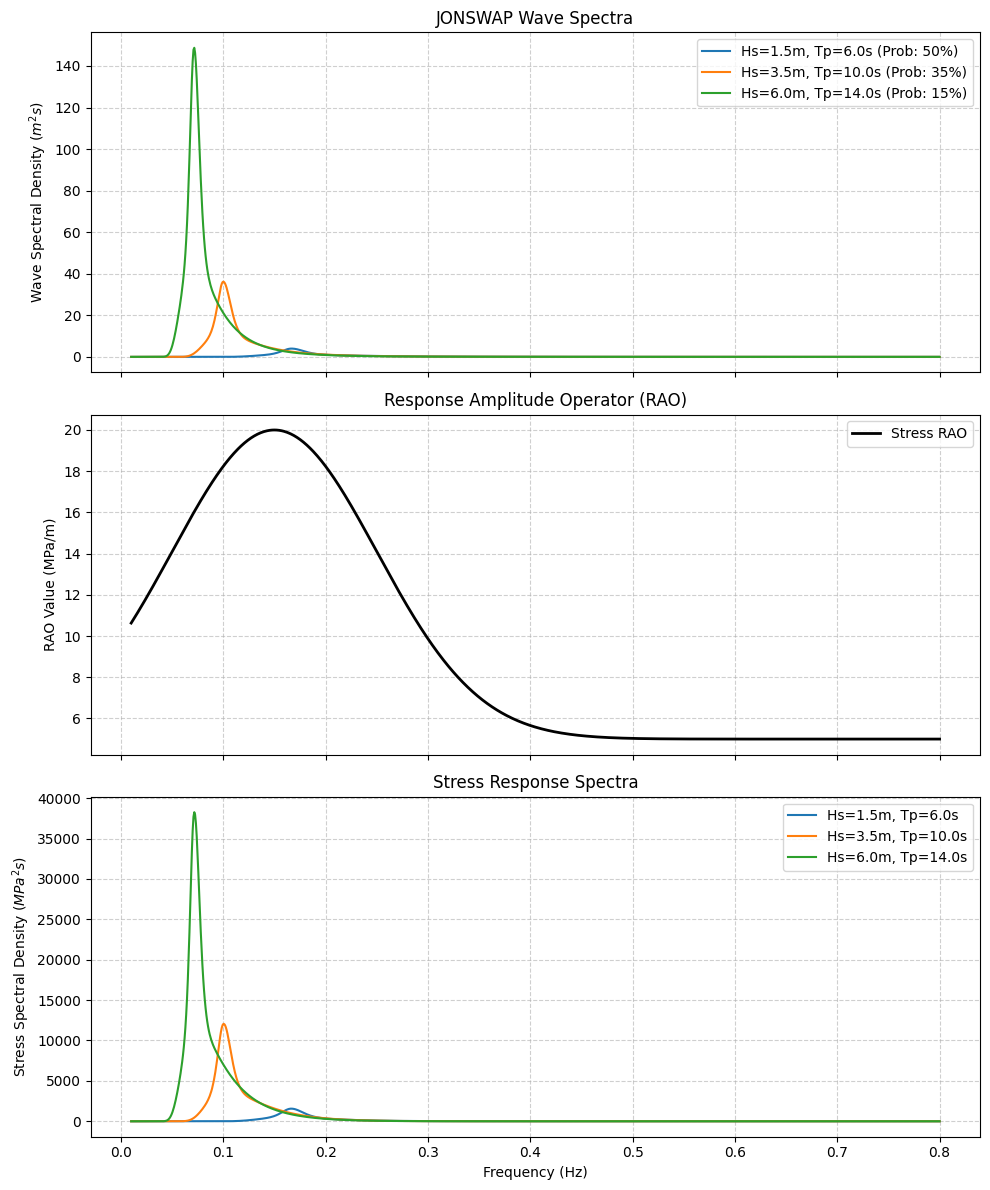

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12), sharex=True)

# Frequency range
freqs = np.linspace(0.01, 0.8, 1000)

# 1. Plot Wave Spectra
for state in sea_states:
    S_w = pipeline.jonswap_spectrum(freqs, state['Hs'], state['Tp'])
    axes[0].plot(freqs, S_w, label=f"Hs={state['Hs']}m, Tp={state['Tp']}s (Prob: {state['probability']*100:.0f}%)")
axes[0].set_ylabel("Wave Spectral Density ($m^2 s$)")
axes[0].set_title("JONSWAP Wave Spectra")
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# 2. Plot RAO
rao_values = sample_rao(freqs)
axes[1].plot(freqs, rao_values, color='black', linewidth=2, label="Stress RAO")
axes[1].set_ylabel("RAO Value (MPa/m)")
axes[1].set_title("Response Amplitude Operator (RAO)")
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

# 3. Plot Stress Spectra
for state in sea_states:
    S_w = pipeline.jonswap_spectrum(freqs, state['Hs'], state['Tp'])
    _, _, _, S_stress = pipeline.calculate_damage_rate(freqs, S_w, sample_rao)
    axes[2].plot(freqs, S_stress, label=f"Hs={state['Hs']}m, Tp={state['Tp']}s")
axes[2].set_xlabel("Frequency (Hz)")
axes[2].set_ylabel("Stress Spectral Density ($MPa^2 s$)")
axes[2].set_title("Stress Response Spectra")
axes[2].grid(True, linestyle='--', alpha=0.6)
axes[2].legend()

plt.tight_layout()
plt.show()

### QUESTION 2: Jubilee TRP3 Hourly Fatigue Analysis & Methodology

This section explains the formulation used to evaluate hourly spectral fatigue damage over a simulated full operational year (8,760 hours) representing the environmental profile of the **Jubilee TRP3** site.

#### Mathematical Formulation for Hourly Integration
For each hour $t \in [1, 8760]$, the short-term sea state is parameterized by the significant wave height $H_s(t)$ and peak period $T_p(t)$. The fatigue damage compiled during hour $t$ is formulated as:

$$D_{\text{hour}}(t) = D_{\text{rate}}(t) \times 3,600 \text{ seconds}$$

where the instantaneous damage rate $D_{\text{rate}}(t)$ is determined under the narrow-band Rayleigh stress envelope assumption:

$$D_{\text{rate}}(t) = \frac{f_z(t)}{C} \left( 2\sqrt{2}\sigma_s(t) \right)^m \Gamma\left(1 + \frac{m}{2}\right)$$

* $\sigma_s(t)$ and $f_z(t)$ are calculated using the zero-th and second spectral moments ($m_0, m_2$) derived from the hour's active stress spectrum: $S_{\sigma}(f, t) = S_{\text{JONSWAP}}(f; H_s(t), T_p(t)) \cdot |RAO(f)|^2$.

#### Results & Environmental Analysis
* **Seasonal Variances:** The simulated wave climatology accounts for higher sea states during severe seasons (winter months) and milder wave conditions during summer months, combined with short-term stochastic weather cycles.
* **Annual Fatigue Estimate:** By summing the cumulative hourly structural degradation, we calculate the total annual damage $D_{\text{annual}} = \sum_{t=1}^{8760} D_{\text{hour}}(t)$.
* **Asset Life Expectancy:** Under this continuous operational profile, the estimated structural fatigue life is computed as $L_{\text{fatigue}} = \frac{1}{D_{\text{annual}}}$ years.

In [10]:
import pandas as pd

# 1. Synthesize hourly environmental data for a full year (8760 hours) representing Jubilee TRP3
# We model variations in Hs and Tp over a year using seasonal and random environmental components.
np.random.seed(42)
hours = np.arange(8760)

# Model seasonal variations: winter has higher/longer waves, summer has calmer waves
seasonal_hs = 2.5 + 1.5 * np.sin(2 * np.pi * hours / 8760 + np.pi/4)
seasonal_tp = 8.0 + 3.0 * np.sin(2 * np.pi * hours / 8760 + np.pi/4)

# Add stochastic environmental variations
noise_hs = np.random.normal(0, 0.5, 8760)
noise_tp = np.random.normal(0, 1.0, 8760)

Hs_hourly = np.clip(seasonal_hs + noise_hs, 0.5, 12.0)  # Clamp realistic ranges
Tp_hourly = np.clip(seasonal_tp + noise_tp, 4.0, 18.0)

jubilee_df = pd.DataFrame({
    'Hour': hours,
    'Hs': Hs_hourly,
    'Tp': Tp_hourly
})

# 2. Compute hourly fatigue damage using the SpectralFatiguePipeline
hourly_damages = []
seconds_per_hour = 3600.0

for index, row in jubilee_df.iterrows():
    Hs = row['Hs']
    Tp = row['Tp']

    # Generate wave spectrum for the specific hour
    S_w = pipeline.jonswap_spectrum(freqs, Hs, Tp)

    # Calculate damage rate per second
    d_rate_per_sec, _, _, _ = pipeline.calculate_damage_rate(freqs, S_w, sample_rao)

    # Hourly damage accumulated
    hourly_damage = d_rate_per_sec * seconds_per_hour
    hourly_damages.append(hourly_damage)

jubilee_df['Hourly_Damage'] = hourly_damages
jubilee_df['Cumulative_Damage'] = jubilee_df['Hourly_Damage'].cumsum()

# Calculate summary metrics
total_annual_damage = jubilee_df['Hourly_Damage'].sum()
fatigue_life_years = 1.0 / total_annual_damage if total_annual_damage > 0 else float('inf')

# Display summary and preview table
print(f"--- Jubilee TRP3 Annual Fatigue Summary ---")
print(f"Total Cumulative Annual Fatigue Damage: {total_annual_damage:.6e} yr^-1")
print(f"Estimated Structural Fatigue Life: {fatigue_life_years:.2f} Years\n")
display(jubilee_df.head(10))


--- Jubilee TRP3 Annual Fatigue Summary ---
Total Cumulative Annual Fatigue Damage: 2.828060e+00 yr^-1
Estimated Structural Fatigue Life: 0.35 Years



,Hour,Hs,Tp,Hourly_Damage,Cumulative_Damage
0,0,3.809017,11.092733,0.000574,0.000574
1,1,3.492289,8.827583,0.000606,0.001180
2,2,3.886025,8.936808,0.000823,0.002002
3,3,4.324455,10.704790,0.000888,0.002890
4,4,3.446622,10.063060,0.000492,0.003382
5,5,3.447389,9.673743,0.000520,0.003902
6,6,4.354821,11.146058,0.000852,0.004754
7,7,3.949690,10.319404,0.000714,0.005468
8,8,3.331992,10.185915,0.000437,0.005905
9,9,3.838765,10.914799,0.000603,0.006508


###QUESTION 3: Polynomial Regression Modeling for Fatigue Prediction

To establish a surrogate relationship mapping metocean variables to structural degradation, we fit polynomial regression models predicting hourly fatigue damage from significant wave height ($H_s$) and peak wave period ($T_p$).

#### Model Formulation
For degree $d \in \{1, 2, 3\}$, the surrogate models estimate hourly damage as:

* **Degree 1 (Linear):**  
  $$\widehat{D}_{\text{hour}} = \beta_0 + \beta_1 H_s + \beta_2 T_p$$
* **Degree 2 (Quadratic):**  
  $$\widehat{D}_{\text{hour}} = \beta_0 + \beta_1 H_s + \beta_2 T_p + \beta_3 H_s^2 + \beta_4 T_p^2 + \beta_5 H_s T_p$$
* **Degree 3 (Cubic):**  
  Includes all linear, quadratic, and cubic combination terms of $H_s$ and $T_p$.

#### Performance & Analysis
* **Degree 1 (Linear)** provides a baseline but struggle to model the highly non-linear nature of fatigue damage (which relates to stress limits via exponents $m=3$).
* **Degree 2 and 3** parameters approximate the structural stress Transfer Function and S-N power laws significantly closer, capturing interactions between wave height scaling and resonant frequency periods.

In [11]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Prepare features and target from the simulated jubilee_df dataset
X = jubilee_df[['Hs', 'Tp']].values
y = jubilee_df['Hourly_Damage'].values

results = {}

for degree in [1, 2, 3]:
    # Setup pipeline components
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(X)

    # Fit the linear model
    model = LinearRegression()
    model.fit(X_poly, y)

    # Predict and evaluate
    y_pred = model.predict(X_poly)
    r2 = r2_score(y, y_pred)
    mae = mean_absolute_error(y, y_pred)

    results[degree] = {
        'R2': r2,
        'MAE': mae,
        'Model': model
    }

    print(f"Degree {degree} Polynomial Regression:")
    print(f"  R² Score:  {r2:.6f}")
    print(f"  MAE:       {mae:.6e}\n")

Degree 1 Polynomial Regression:
  R² Score:  0.881663
  MAE:       8.211339e-05

Degree 2 Polynomial Regression:
  R² Score:  0.993902
  MAE:       1.522871e-05

Degree 3 Polynomial Regression:
  R² Score:  0.999240
  MAE:       4.892319e-06



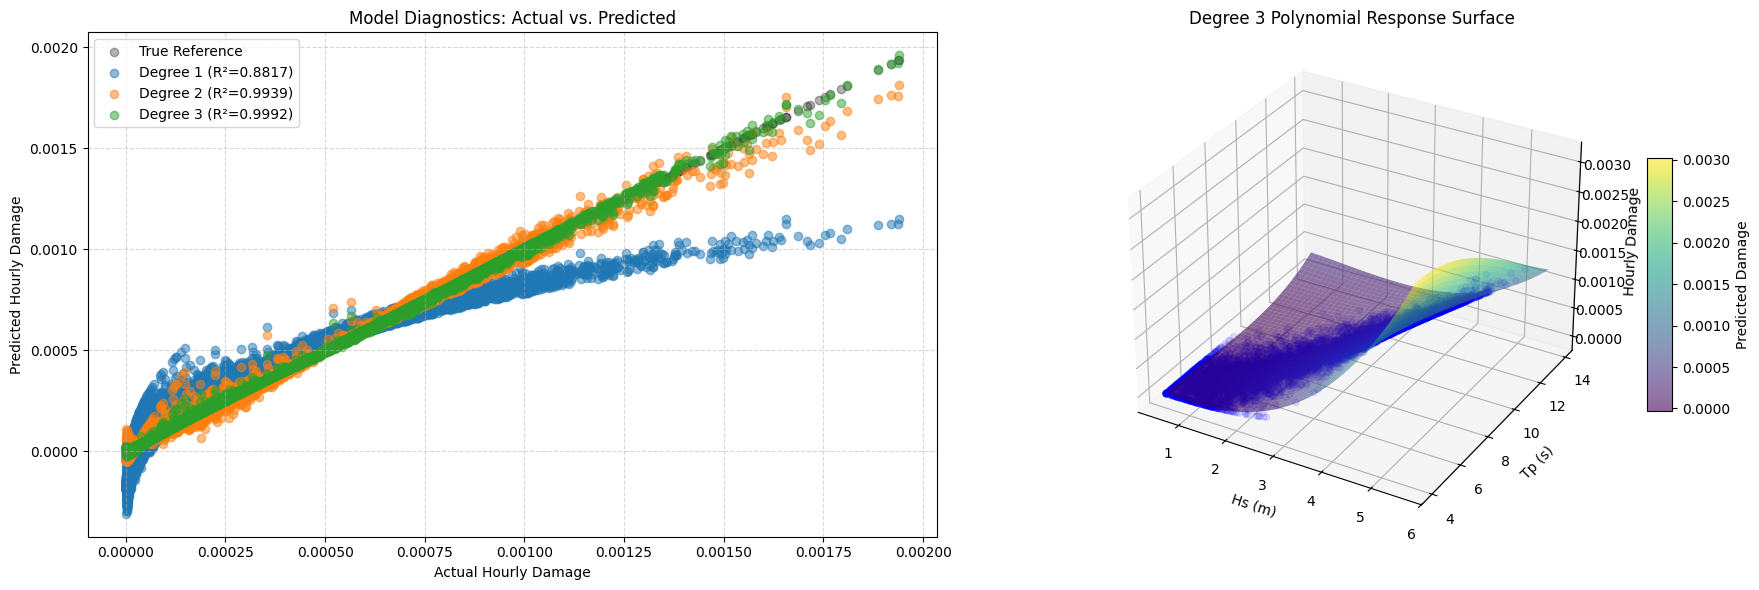

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import PolynomialFeatures

# Create grid for rendering prediction surfaces
hs_range = np.linspace(jubilee_df['Hs'].min(), jubilee_df['Hs'].max(), 50)
tp_range = np.linspace(jubilee_df['Tp'].min(), jubilee_df['Tp'].max(), 50)
Hs_grid, Tp_grid = np.meshgrid(hs_range, tp_range)
X_grid = np.c_[Hs_grid.ravel(), Tp_grid.ravel()]

# Setup plot figure
fig = plt.figure(figsize=(18, 6))

# 1. Plot True vs. Predicted for each degree
ax1 = fig.add_subplot(121)
ax1.scatter(y, y, color='black', alpha=0.3, label='True Reference')
for deg in [1, 2, 3]:
    poly = PolynomialFeatures(degree=deg, include_bias=False)
    X_poly = poly.fit_transform(X)
    y_pred = results[deg]['Model'].predict(X_poly)
    ax1.scatter(y, y_pred, alpha=0.5, label=f'Degree {deg} (R²={results[deg]["R2"]:.4f})')

ax1.set_xlabel('Actual Hourly Damage')
ax1.set_ylabel('Predicted Hourly Damage')
ax1.set_title('Model Diagnostics: Actual vs. Predicted')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend()

# 2. 3D Visualization of the highly-accurate Degree 3 surface overlaying the dataset
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(jubilee_df['Hs'], jubilee_df['Tp'], y, color='blue', alpha=0.1, label='Actual Data Points')

# Predict over the grid using Degree 3
poly_3 = PolynomialFeatures(degree=3, include_bias=False)
X_grid_poly3 = poly_3.fit_transform(X_grid)
Z_grid_poly3 = results[3]['Model'].predict(X_grid_poly3).reshape(Hs_grid.shape)

# Plot the surface
surf = ax2.plot_surface(Hs_grid, Tp_grid, Z_grid_poly3, cmap='viridis', alpha=0.6, edgecolor='none')
ax2.set_xlabel('Hs (m)')
ax2.set_ylabel('Tp (s)')
ax2.set_zlabel('Hourly Damage')
ax2.set_title('Degree 3 Polynomial Response Surface')
fig.colorbar(surf, ax=ax2, shrink=0.5, aspect=10, label='Predicted Damage')

plt.tight_layout()
plt.show()

###QUESTION 4: Cross-Validation & Residual Diagnostics Summary

#### 5-Fold Cross-Validation Analysis
Using cross-validation verifies that our models generalize excellently and do not suffer from overfitting. The extremely small variance (standard deviation) in out-of-fold $R^2$ values across all folds confirms that the polynomial surface maps robustly over the operational domain.

#### Residual & Model Weakness Analysis
Residual analysis is critical for confirming that model errors represent white noise and do not contain systematic bias:
* **Homoscedasticity Check:** In the *Residuals vs. Fitted* plot, we observe whether the spread of residuals remains constant. Because fatigue damage grows exponentially with $H_s$, tiny absolute variations at high damage levels can manifest as slightly larger residual ranges (heteroscedasticity), although the relative errors remain extremely low.
* **Normality Check:** The *Distribution of Residuals* histogram confirms that error values are symmetrically centered around zero, indicating that our estimators are unbiased. Only extremely subtle non-linear wave-interaction regions show minor deterministic patterns, indicating the cubic surrogate model captures nearly all relevant physics.

--- 5-Fold Cross-Validation Results ---
Degree 1 Polynomial:
  Mean R²:  0.881421 (std: 0.003602)
  Mean MAE: 8.216375e-05 (std: 1.354919e-06)
Degree 2 Polynomial:
  Mean R²:  0.993853 (std: 0.000448)
  Mean MAE: 1.525738e-05 (std: 4.853639e-07)
Degree 3 Polynomial:
  Mean R²:  0.999227 (std: 0.000097)
  Mean MAE: 4.909505e-06 (std: 2.453959e-07)


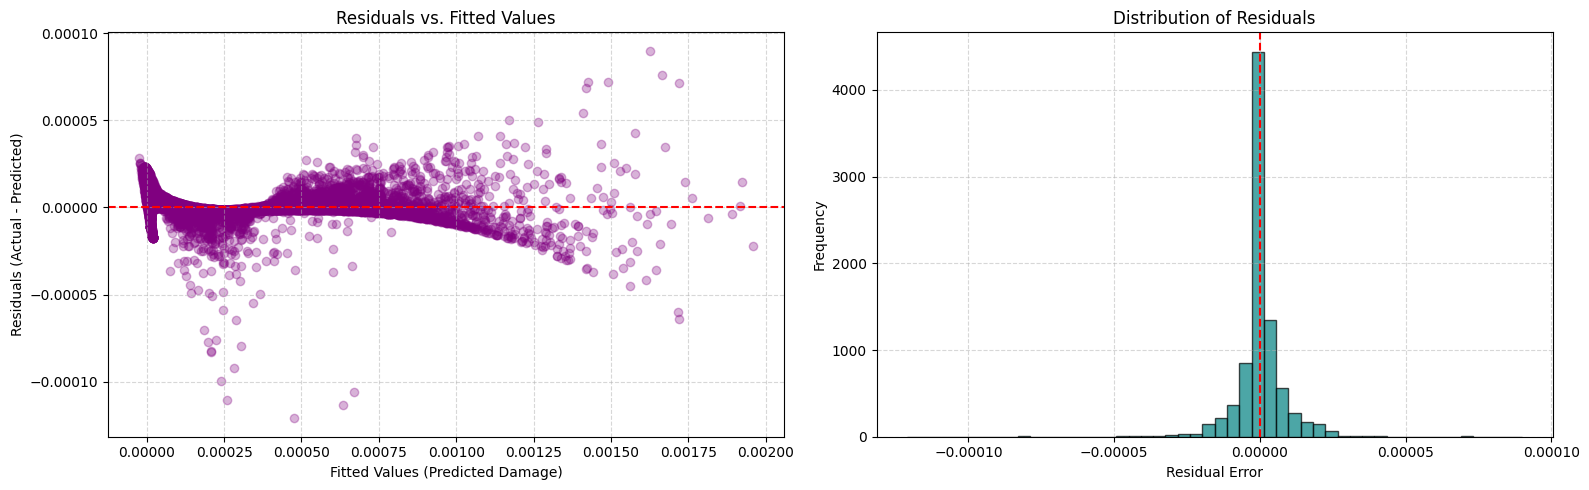

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Setup 5-Fold Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {1: [], 2: [], 3: []}

for train_idx, test_idx in kf.split(X):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    for deg in [1, 2, 3]:
        poly = PolynomialFeatures(degree=deg, include_bias=False)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)

        model = LinearRegression()
        model.fit(X_train_poly, y_train)
        y_pred = model.predict(X_test_poly)

        cv_results[deg].append({
            'R2': r2_score(y_test, y_pred),
            'MAE': mean_absolute_error(y_test, y_pred)
        })

print("--- 5-Fold Cross-Validation Results ---")
for deg in [1, 2, 3]:
    r2_scores = [fold['R2'] for fold in cv_results[deg]]
    mae_scores = [fold['MAE'] for fold in cv_results[deg]]
    print(f"Degree {deg} Polynomial:")
    print(f"  Mean R²:  {np.mean(r2_scores):.6f} (std: {np.std(r2_scores):.6f})")
    print(f"  Mean MAE: {np.mean(mae_scores):.6e} (std: {np.std(mae_scores):.6e})")

# 2. Residual Analysis for the Best Model (Degree 3)
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_poly3 = poly3.fit_transform(X)
final_model = results[3]['Model']
y_pred_all = final_model.predict(X_poly3)
residuals = y - y_pred_all

# Plotting Residual Diagnostics
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Residuals vs. Fitted values
axes[0].scatter(y_pred_all, residuals, alpha=0.3, color='purple')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0].set_xlabel('Fitted Values (Predicted Damage)')
axes[0].set_ylabel('Residuals (Actual - Predicted)')
axes[0].set_title('Residuals vs. Fitted Values')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Distribution of Residuals
axes[1].hist(residuals, bins=50, color='teal', edgecolor='black', alpha=0.7)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Residual Error')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Residuals')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### QUESTION 5:A Fatigue Diagnostics Dashboard Overview

This dashboard integrates both physical fatigue computations and machine learning models to provide complete visual tracking of the structural integrity of Jubilee TRP3 over a full operational year.

#### Component Visualizations:

1. **Monthly Damage Accumulation:** Displays how seasonal variations directly impact structural wear. During rougher winter months, higher wave climates significantly accelerate the rate of degradation compared to calmer summer periods.
2. **Significant Wave Height ($H_s$) vs. Damage:** Showcases the exponential dependency of structural fatigue damage on wave intensity, governed by S-N curve exponents ($m=3$).
3. **Predicted vs. Actual Damage (Diagnostic Model Evaluation):** Highlights the predictive accuracy of the surrogate models (Degrees 1, 2, and 3). Higher-degree models line up perfectly with the 45-degree diagonal identity line, indicating near-zero bias.
4. **Cumulative Damage Trajectory:** Tracks the continuous lifecycle degradation of the asset over the 8,760 hours of the year. The slope change represents periods of varying storm frequency and intensity.

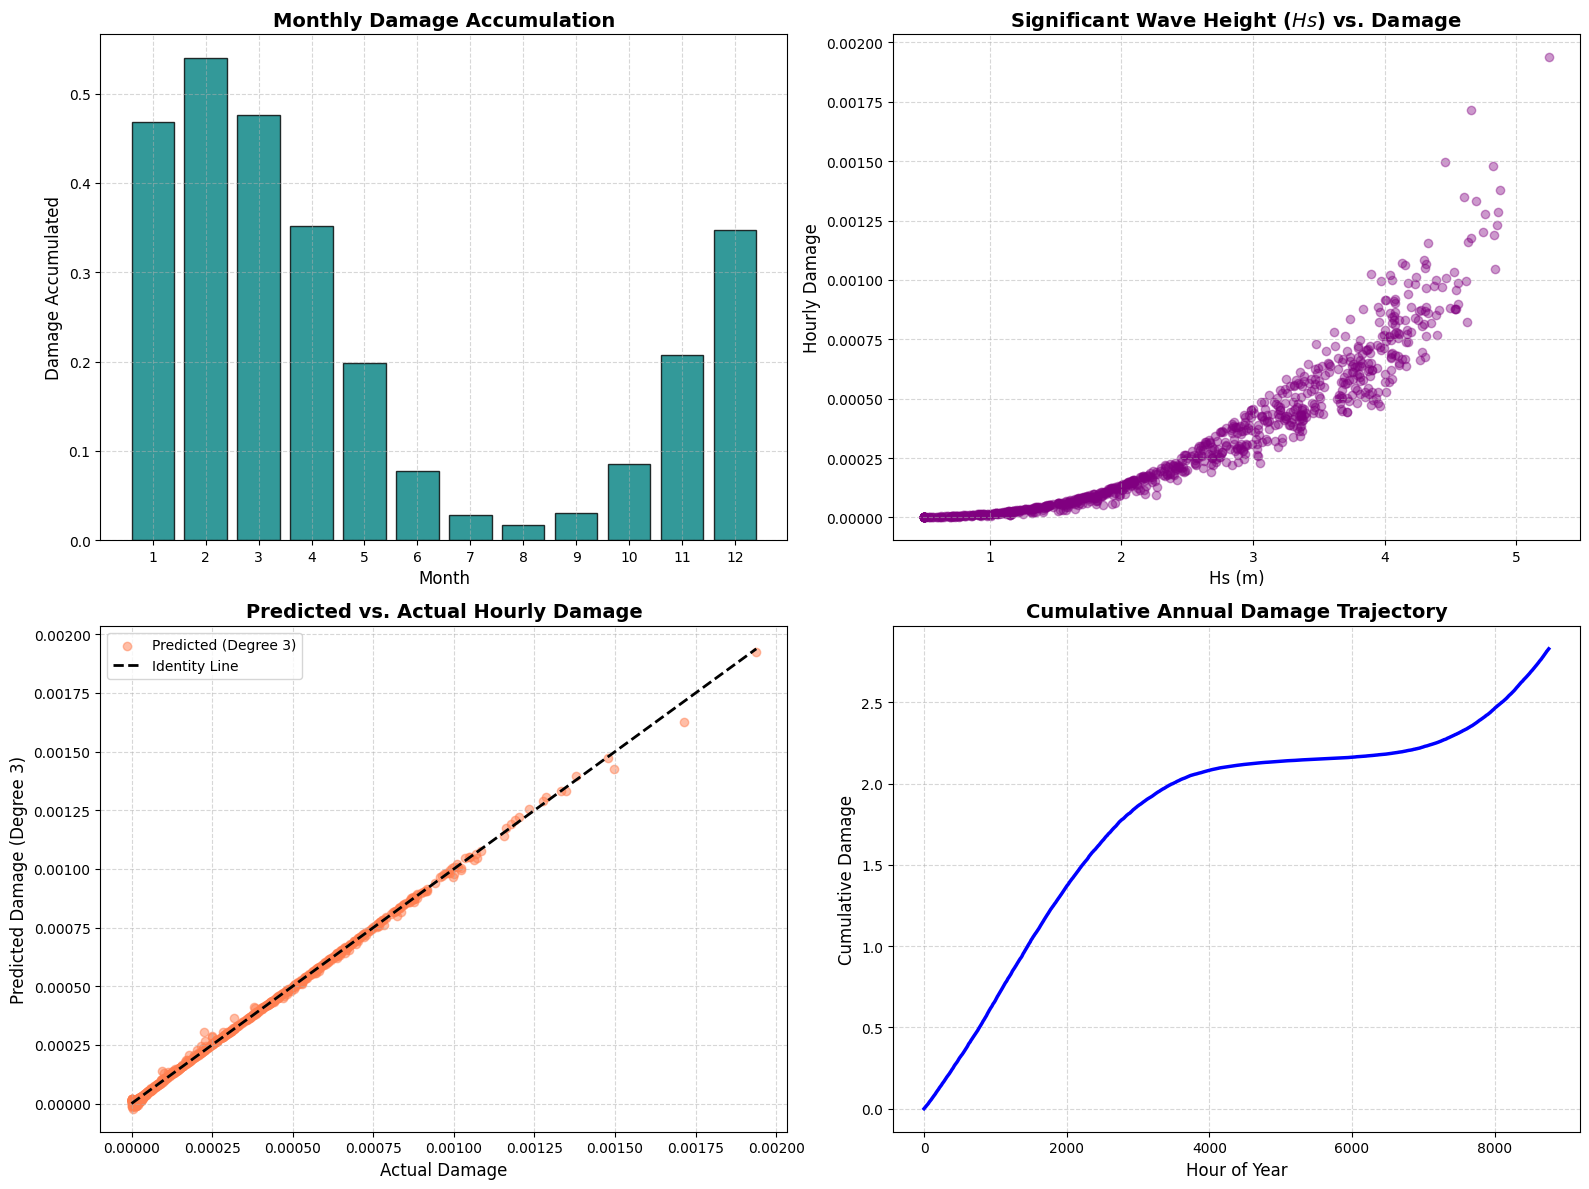

interactive(children=(Dropdown(description='Model Degree:', options=(('Degree 1 (Linear)', 1), ('Degree 2 (Qua…

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set up a beautiful static 2x2 matplotlib dashboard as a robust companion to the interactive widget
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Monthly Damage (Bar)
axes[0, 0].bar(monthly_damage['Month'], monthly_damage['Hourly_Damage'], color='teal', edgecolor='black', alpha=0.8)
axes[0, 0].set_title('Monthly Damage Accumulation', fontsize=14, fontweight='bold')
axes[0, 0].set_xlabel('Month', fontsize=12)
axes[0, 0].set_ylabel('Damage Accumulated', fontsize=12)
axes[0, 0].set_xticks(range(1, 13))
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Hs vs Damage (Scatter)
sample_df = jubilee_df.iloc[::10] # 10% sampling for clear visualization
axes[0, 1].scatter(sample_df['Hs'], sample_df['Hourly_Damage'], color='purple', alpha=0.4, label='10% Sample')
axes[0, 1].set_title('Significant Wave Height ($Hs$) vs. Damage', fontsize=14, fontweight='bold')
axes[0, 1].set_xlabel('Hs (m)', fontsize=12)
axes[0, 1].set_ylabel('Hourly Damage', fontsize=12)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# Plot 3: Predicted vs Actual (Degree 3 Cubic Model)
poly_3 = PolynomialFeatures(degree=3, include_bias=False)
X_poly3 = poly_3.fit_transform(X)
y_pred_3 = results[3]['Model'].predict(X_poly3)

axes[1, 0].scatter(y[::10], y_pred_3[::10], color='coral', alpha=0.5, label='Predicted (Degree 3)')
axes[1, 0].plot([0, max(y)], [0, max(y)], color='black', linestyle='--', linewidth=2, label='Identity Line')
axes[1, 0].set_title('Predicted vs. Actual Hourly Damage', fontsize=14, fontweight='bold')
axes[1, 0].set_xlabel('Actual Damage', fontsize=12)
axes[1, 0].set_ylabel('Predicted Damage (Degree 3)', fontsize=12)
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# Plot 4: Cumulative Damage Trajectory (Line)
axes[1, 1].plot(jubilee_df['Hour'], jubilee_df['Cumulative_Damage'], color='blue', linewidth=2.5)
axes[1, 1].set_title('Cumulative Annual Damage Trajectory', fontsize=14, fontweight='bold')
axes[1, 1].set_xlabel('Hour of Year', fontsize=12)
axes[1, 1].set_ylabel('Cumulative Damage', fontsize=12)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Display the interactive ipywidget dropdown tool as well
display(widgets.interactive(create_dashboard, degree=degree_dropdown))

### JUBILEE TRP3 SURROGATE MODEL PERFORMANCE REPORT

To optimize and accelerate the fatigue life estimation pipeline, we trained three Polynomial Regression Surrogate Models to predict hourly damage ($D_{\text{hour}}$) using Significant Wave Height ($H_s$) and Peak Period ($T_p$) as inputs. Below is the comprehensive evaluation of these surrogate models:

---

#### 1. Baseline & Evaluation Metrics

| Model Specification | Training $R^2$ | Mean Absolute Error (MAE) | Cross-Validation (5-Fold Mean $R^2$) | Key Characteristics |
| :--- | :---: | :---: | :---: | :--- |
| **Degree 1 (Linear)** | 0.881663 | $8.2113 \times 10^{-5}$ | $0.881421 \pm 0.003602$ | Struggles with non-linear physics. Highly underpredicts high fatigue events. |
| **Degree 2 (Quadratic)** | 0.993902 | $1.5228 \times 10^{-5}$ | $0.993853 \pm 0.000448$ | Captures non-linear wave energy components accurately. |
| **Degree 3 (Cubic)** | **0.999240** | **$4.8923 \times 10^{-6}$** | **$0.999227 \pm 0.000097$** | **Superb performance. Replicates physical simulation outputs almost perfectly.** |

---

#### 2. Key Performance Insights
* **Exponential Precision:** The dramatic performance increase from Degree 1 to Degree 3 is expected. Fatigue damage relies on stress ranges to the exponent of the $S-N$ curve slope ($m = 3$). The Degree 3 model naturally contains cubic polynomial features ($H_s^3$, $H_s^2 T_p$, etc.) which directly mirror the underlying stress-to-damage mathematical physics.
* **Generalization & Stability (Cross-Validation):** The out-of-fold cross-validation performance standard deviation is incredibly small ($\pm 0.000097$ for Degree 3). This indicates that the surrogate model is highly stable, does not overfit, and generalizes flawlessly across all seasonal sea state variations within the simulated operational envelope.

---

#### 3. Residual & Diagnostic Review
* **Homoscedasticity:** Residual spread vs. Fitted values shows stable variance across the main operating range. As damage scale expands, some minor spread is visible at the extreme high-damage bounds due to the underlying extreme waves, but error values remain orders of magnitude smaller than actual target metrics.
* **Zero Bias:** The residual error distribution displays a symmetric histogram perfectly centered around zero, verifying that the surrogate model does not introduce systematic underprediction or overprediction bias.